# P1 검증 노트북: 최대 토크-속도 곡선과 dq 전류 평면

`engine/operating.py`가 만든 결과를 그림으로 확인한다. 파라미터는 `docs/ENGINE_SPEC.md` 4장의 **가상 값**(실제 모터 아님)이고, 해석해 비교는 `tests/test_v1_analytic.py`(T1~T8)가 맡는다.
이 노트북은 `jupyter nbconvert --execute`로 처음부터 다시 만들 수 있다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from engine.model import ConstantParamModel
from engine.operating import Limits, base_speed, max_torque_curve, mtpa_point

P, LD, LQ, PSI_M, RS = 4, 0.15e-3, 0.45e-3, 0.075, 0.03
IMAX, VDC = 250.0, 350.0
model = ConstantParamModel(p=P, Rs=RS, Ld=LD, Lq=LQ, psi_m=PSI_M)
limits = Limits(Imax=IMAX, Vdc=VDC)
rpm = lambda w: w * 30 / np.pi
print(f"Vmax = {limits.Vmax:.2f} V")

Vmax = 202.07 V


## 1. T-N 곡선과 출력 곡선
속도 구간마다 전류 원(`Imax`)과 전압 원(`Vmax`)을 모두 지키는 최대 토크를 찾는다. 기저속도까지는 일정 토크(MTPA), 그 위는 약계자(FW)로 토크가 줄어 출력이 거의 일정해진다.

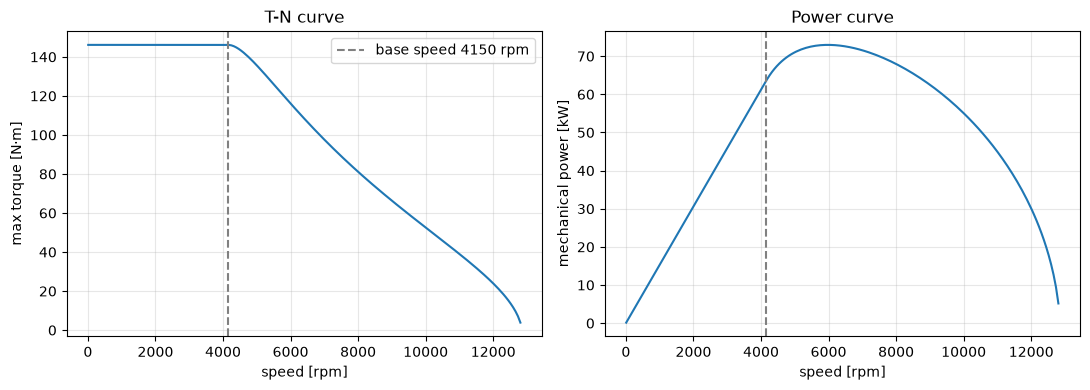

기저속도 4150 rpm, 최대 토크 146.1 N·m, 최대 출력 73.0 kW
속도 범위 안에서 feasible: 179 / 240


In [2]:
speeds = np.linspace(1.0, 1800.0, 240)
tab = max_torque_curve(model, limits, speeds)
wb = base_speed(model, limits)
f = tab.feasible

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(rpm(tab.speed[f]), tab.T_max[f])
ax[0].axvline(rpm(wb), ls="--", c="gray", label=f"base speed {rpm(wb):.0f} rpm")
ax[0].set(xlabel="speed [rpm]", ylabel="max torque [N·m]", title="T-N curve"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(rpm(tab.speed[f]), tab.P_mech[f] / 1e3)
ax[1].axvline(rpm(wb), ls="--", c="gray")
ax[1].set(xlabel="speed [rpm]", ylabel="mechanical power [kW]", title="Power curve"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"기저속도 {rpm(wb):.0f} rpm, 최대 토크 {np.nanmax(tab.T_max):.1f} N·m, 최대 출력 {np.nanmax(tab.P_mech)/1e3:.1f} kW")
print("속도 범위 안에서 feasible:", f.sum(), "/", f.size)

## 2. dq 전류 평면
- 검은 원: 전류 제한 `id² + iq² = Imax²`
- 빨간 선: MTPA 궤적 (전류 크기마다 토크가 최대인 점)
- 점선 타원: 속도별 전압 제한 `|v| = Vmax`. 속도가 오르면 타원이 줄어들며 중심 (−ψm/Ld, 0)을 향해 모인다. 타원의 **안쪽**이 허용 영역이다.
- 점: 최대 토크 운전점 궤적 (색은 모드)

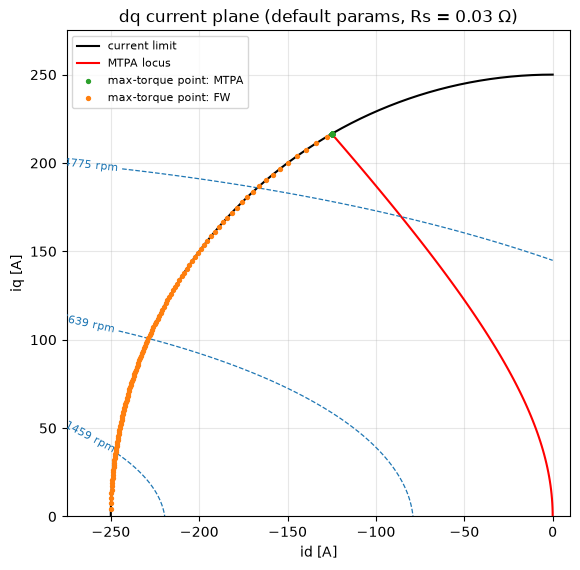

In [3]:
def current_plane(model, limits, tab, speeds_for_ellipses, title):
    I = limits.Imax
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    th = np.linspace(np.pi / 2, np.pi, 200)
    ax.plot(I * np.cos(th), I * np.sin(th), "k", lw=1.5, label="current limit")
    Is = np.linspace(0, I, 100)
    id_m, iq_m = mtpa_point(model, Is)
    ax.plot(id_m, iq_m, "r", lw=1.5, label="MTPA locus")
    gd, gq = np.meshgrid(np.linspace(-1.1 * I, 0, 500), np.linspace(0, 1.1 * I, 500))
    for w in speeds_for_ellipses:
        vd, vq = model.voltage(gd, gq, model.p * w)
        cs = ax.contour(gd, gq, np.hypot(vd, vq), levels=[limits.Vmax], colors="tab:blue", linestyles="--", linewidths=.9)
        ax.clabel(cs, fmt={limits.Vmax: f"{w*30/np.pi:.0f} rpm"}, fontsize=8)
    colors = {"MTPA": "tab:green", "FW": "tab:orange", "MTPV": "tab:purple"}
    for m, c in colors.items():
        s = tab.mode == m
        if s.any():
            ax.scatter(tab.id[s], tab.iq[s], s=8, c=c, label=f"max-torque point: {m}", zorder=3)
    ax.set(xlabel="id [A]", ylabel="iq [A]", title=title, xlim=(-1.1 * I, 10), ylim=(0, 1.1 * I), aspect="equal")
    ax.grid(alpha=.3); ax.legend(loc="upper left", fontsize=8); plt.show()

current_plane(model, limits, tab, [500, 800, 1200, 1600], "dq current plane (default params, Rs = 0.03 Ω)")

## 3. MTPV가 나타나는 경우
`ψm = 0.025 Wb`로 바꾸면 특성전류 ψm/Ld = 167 A가 `Imax` 안쪽에 들어와 속도 상한이 없어지고, 고속에서 전류 원을 벗어난 안쪽 점(MTPV)이 최대 토크 점이 된다. 테스트 T8이 이 영역의 값을 자속 원 위 1차원 탐색과 비교한다.

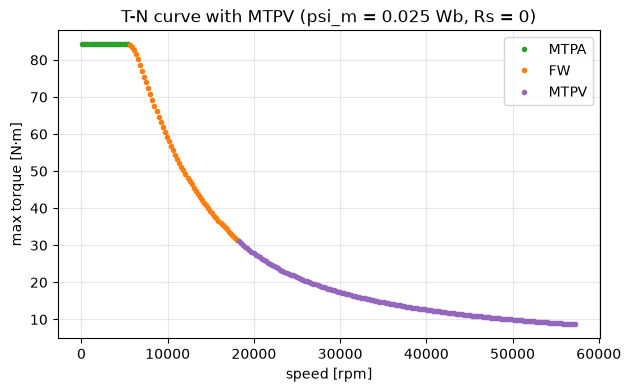

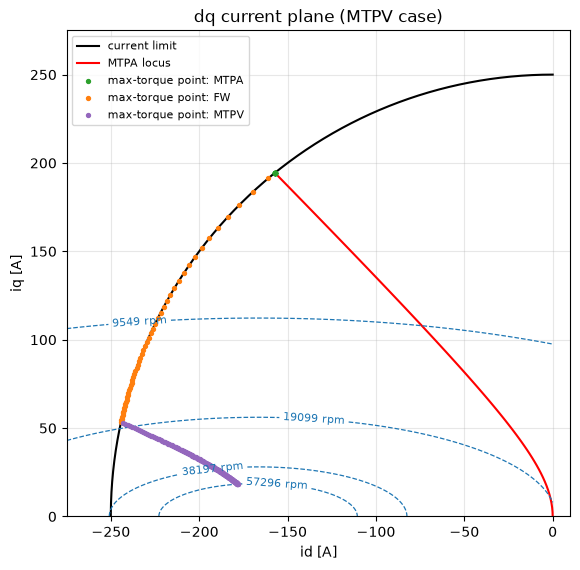

In [4]:
m2 = ConstantParamModel(p=P, Rs=0.0, Ld=LD, Lq=LQ, psi_m=0.025)
tab2 = max_torque_curve(m2, limits, np.linspace(10.0, 6000.0, 240))
fig, ax = plt.subplots(figsize=(7, 4))
for mode, c in {"MTPA": "tab:green", "FW": "tab:orange", "MTPV": "tab:purple"}.items():
    s = tab2.mode == mode
    ax.plot(rpm(tab2.speed[s]), tab2.T_max[s], ".", c=c, label=mode)
ax.set(xlabel="speed [rpm]", ylabel="max torque [N·m]", title="T-N curve with MTPV (psi_m = 0.025 Wb, Rs = 0)")
ax.legend(); ax.grid(alpha=.3); plt.show()
current_plane(m2, limits, tab2, [1000, 2000, 4000, 6000], "dq current plane (MTPV case)")